# Exp 3 – Stronger Regularization | Random Forest

1. One-Hot Encoding (OHE) is applied to categorical features.
2. Class imbalance is handled using class_weight='balanced'.
3. The original training data is further split into training (80%) and validation (20%), keeping the test set untouched.
4. RandomizedSearchCV with 5-Fold Stratified CV is used to find the best hyperparameters based on PR-AUC, with stronger regularization.
5. The best model generates probabilities on the validation set.
6. Validation probabilities are used to find the best classification threshold based on F1 Score.
7. The selected threshold is applied to training, validation, and test probabilities to generate:
   0 = Retained | 1 = Churned.
8. Model performance is evaluated using classification metrics, confusion matrix, and cross-validation.
9. Feature importance is analysed to identify the most influential features.

## 0. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

## 1. Separate Features and Target

In [3]:
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total missing values:", X.isna().sum().sum())
print("\nTarget Distribution:")
print(y.value_counts())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Total missing values: 33864

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64


## 2. Original Train-Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Data:", X_train.shape)
print("Original Test Data:", X_test.shape)


Original Training Data: (11684, 104)
Original Test Data: (2922, 104)


## 3. Internal Train-Validation Split

In [5]:
# Keep the original test set untouched.
# Use an internal validation set for threshold selection.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=21,
    stratify=y_train
)

print("\nModel Training Data:", X_fit.shape)
print("Threshold Validation Data:", X_val.shape)


Model Training Data: (9347, 104)
Threshold Validation Data: (2337, 104)


## 4. Identify Categorical and Numerical Columns

In [6]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", categorical_cols)
print("Numerical Columns:", len(numerical_cols))


Categorical Columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical Columns: 101


## 5. Preprocessing Pipeline

In [7]:
categorical_pipeline = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=1
)

## 6. Stronger Regularized Random Forest Pipeline

In [8]:
strong_rf_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))
])

## 7. Stratified Cross Validation

In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## 8. Stronger Regularization Search Space

In [10]:
param_grid = {
    'model__n_estimators': [300, 500, 700],
    'model__max_depth': [5, 8, 10, 12],
    'model__min_samples_split': [10, 20, 30],
    'model__min_samples_leaf': [10, 15, 20],
    'model__max_features': [0.3, 0.5, 'sqrt']
}

## 9. Randomized Search CV

In [11]:
random_search = RandomizedSearchCV(
    estimator=strong_rf_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

## 10. Fit Randomized Search

In [12]:
random_search.fit(X_fit, y_fit)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__max_depth': [5, 8, ...], 'model__max_features': [0.3, 0.5, ...], 'model__min_samples_leaf': [10, 15, ...], 'model__min_samples_split': [10, 20, ...], ...}"
,n_iter,30
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


## 11. Best Hyperparameters

In [13]:
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)

print("\nBest CV PR-AUC:")
print(random_search.best_score_)


==== BEST HYPERPARAMETERS ====
{'model__n_estimators': 700, 'model__min_samples_split': 10, 'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': 12}

Best CV PR-AUC:
0.2615202834477929


## 12. Best Regularized Random Forest Model

In [14]:
best_rf_pipeline = random_search.best_estimator_

## 13. Randomized Search Results

In [15]:
search_results_df = pd.DataFrame(
    random_search.cv_results_
).sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")

print(
    search_results_df[[
        'param_model__n_estimators',
        'param_model__max_depth',
        'param_model__min_samples_split',
        'param_model__min_samples_leaf',
        'param_model__max_features',
        'mean_train_score',
        'mean_test_score',
        'std_test_score'
    ]].head(10).round(4).to_string(index=False)
)


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators  param_model__max_depth  param_model__min_samples_split  param_model__min_samples_leaf param_model__max_features  mean_train_score  mean_test_score  std_test_score
                       700                      12                              10                             10                       0.5            0.9365           0.2615          0.0273
                       700                      12                              30                             20                       0.5            0.8224           0.2511          0.0219
                       500                      10                              30                             10                       0.5            0.8243           0.2482          0.0243
                       700                      12                              20                             20                       0.3            0.8200           0.2450          0.0234

## 14. Validation Probabilities

In [16]:
y_prob_val = best_rf_pipeline.predict_proba(X_val)[:, 1]

## 15. Precision-Recall Curve

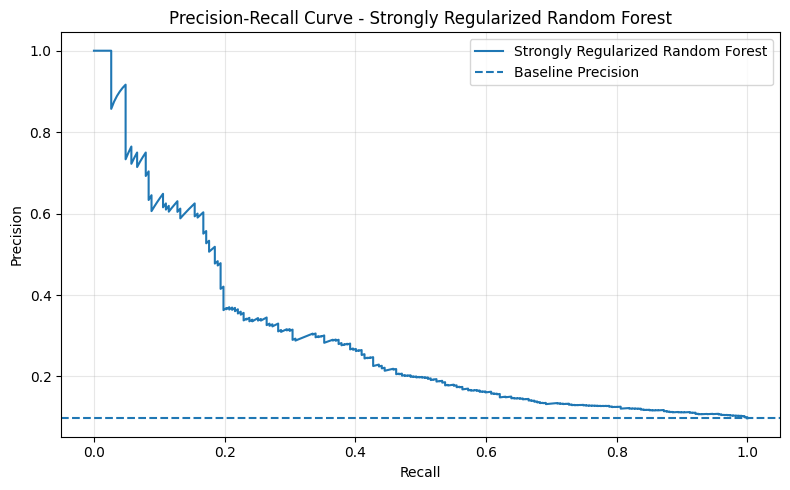

In [17]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='Strongly Regularized Random Forest'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Strongly Regularized Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Fine-Grained Threshold Analysis

In [18]:
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.0985  1.0000    0.1794
      0.06     0.0990  1.0000    0.1801
      0.07     0.0996  1.0000    0.1812
      0.08     0.0998  0.9956    0.1815
      0.09     0.1005  0.9956    0.1826
      0.10     0.1013  0.9956    0.1840
      0.11     0.1022  0.9956    0.1853
      0.12     0.1033  0.9912    0.1870
      0.13     0.1036  0.9780    0.1873
      0.14     0.1052  0.9692    0.1898
      0.15     0.1066  0.9559    0.1918
      0.16     0.1075  0.9251    0.1927
      0.17     0.1110  0.9163    0.1980
      0.18     0.1122  0.8855    0.1992
      0.19     0.1161  0.8722    0.2049
      0.20     0.1176  0.8414    0.2064
      0.21     0.1220  0.8194    0.2125
      0.22     0.1249  0.7930    0.2158
      0.23     0.1283  0.7709    0.2200
      0.24     0.1309  0.7313    0.2221
      0.25     0.1334  0.7004    0.2241
      0.26     0.1380  0.6784    0.2293
      0.27     0.1437  0.6564    0.23

## 17. Threshold Performance Visualization

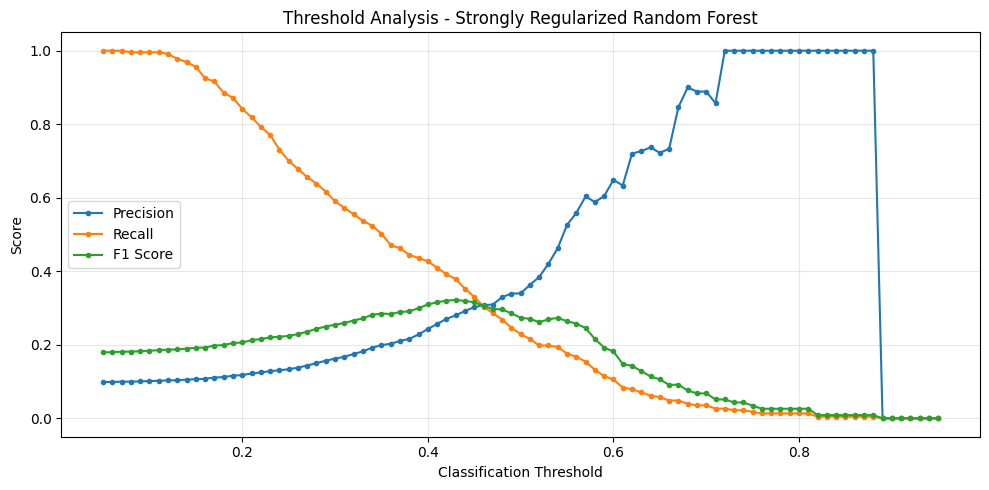

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Strongly Regularized Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 18. Select Best Threshold

In [20]:
best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(),
    'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)

print(
    fine_threshold_df.loc[
        fine_threshold_df['F1 Score'].idxmax()
    ]
)


==== BEST THRESHOLD ====
Best Threshold: 0.43000000000000005
Threshold    0.430000
Precision    0.280130
Recall       0.378855
F1 Score     0.322097
Name: 38, dtype: float64


## 19. Define Metric Function

In [21]:
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

## 20. Training Predictions

In [22]:
y_prob_train = best_rf_pipeline.predict_proba(X_fit)[:, 1]

y_pred_train = (
    y_prob_train >= best_threshold
).astype(int)

## 21. Validation Predictions

In [23]:
y_pred_val = (
    y_prob_val >= best_threshold
).astype(int)

## 22. Test Predictions

In [24]:
y_prob_test = best_rf_pipeline.predict_proba(X_test)[:, 1]

y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)

## 23. Calculate Metrics

In [25]:
train_metrics = calc_metrics(
    y_fit, y_pred_train, y_prob_train
)

validation_metrics = calc_metrics(
    y_val, y_pred_val, y_prob_val
)

test_metrics = calc_metrics(
    y_test, y_pred_test, y_prob_test
)

## 24. Print Train Metrics

In [26]:
print("\n==== TRAIN METRICS ====")

for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TRAIN METRICS ====
Accuracy    : 0.9434
Precision   : 0.6380
Recall      : 0.9648
F1 Score    : 0.7681
ROC-AUC     : 0.9901
PR-AUC      : 0.9172


## 25. Print Validation Metrics

In [27]:
print("\n==== VALIDATION METRICS ====")

for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== VALIDATION METRICS ====
Accuracy    : 0.8451
Precision   : 0.2801
Recall      : 0.3789
F1 Score    : 0.3221
ROC-AUC     : 0.6896
PR-AUC      : 0.2939


## 26. Print Test Metrics

In [28]:
print("\n==== TEST METRICS ====")

for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TEST METRICS ====
Accuracy    : 0.8494
Precision   : 0.2926
Recall      : 0.3873
F1 Score    : 0.3333
ROC-AUC     : 0.6945
PR-AUC      : 0.3171


## 27. Confusion Matrix

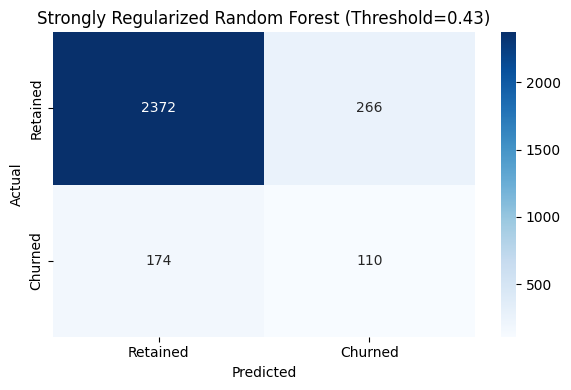

In [29]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Strongly Regularized Random Forest '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

## 28. Classification Report

In [30]:
print("\n==== CLASSIFICATION REPORT ====")

print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.90      0.92      2638
     Churned       0.29      0.39      0.33       284

    accuracy                           0.85      2922
   macro avg       0.61      0.64      0.62      2922
weighted avg       0.87      0.85      0.86      2922



## 29. Cross Validation Performance

In [31]:
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_rf_pipeline,
    X_fit,
    y_fit,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

## 30. Cross Validation Train Scores

In [32]:
print("\n==== CROSS VALIDATION TRAIN SCORES ====")

for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9725, Std: 0.0023
train_Precision - Mean: 0.8461, Std: 0.0162
train_Recall - Mean: 0.8764, Std: 0.0067
train_F1 - Mean: 0.8609, Std: 0.0105
train_ROC_AUC - Mean: 0.9930, Std: 0.0010
train_PR_AUC - Mean: 0.9365, Std: 0.0105


## 31. Cross Validation Validation Scores

In [33]:
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")

for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.8846, Std: 0.0063
test_Precision - Mean: 0.3347, Std: 0.0526
test_Recall - Mean: 0.1872, Std: 0.0350
test_F1 - Mean: 0.2388, Std: 0.0370
test_ROC_AUC - Mean: 0.6848, Std: 0.0185
test_PR_AUC - Mean: 0.2615, Std: 0.0273


## 32. Feature Importance

In [34]:
rf_model = best_rf_pipeline.named_steps['model']

feature_names = (
    best_rf_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = rf_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")
print(feature_importance_df.head(20).to_string(index=False))


==== TOP 20 IMPORTANT FEATURES ====
                   Feature  Importance
        margin_net_pow_ele    0.099895
      cons_last_month_diff    0.033627
   forecast_meter_rent_12m    0.032545
    margin_per_consumption    0.030874
       forecast_cons_ratio    0.029430
price_consumption_exposure    0.027264
              months_activ    0.026246
          margin_per_power    0.025258
     consumption_per_power    0.022372
   price_power_interaction    0.022347
         months_modif_prod    0.020192
     cons_last_month_ratio    0.020093
        forecast_cons_diff    0.018081
         forecast_cons_12m    0.017041
                  cons_12m    0.016882
                   pow_max    0.016437
           cons_last_month    0.016175
   var_year_price_off_peak    0.015765
        margin_per_product    0.015653
            price_off_peak    0.014076


# **Observation: Exp 3 – Stronger Regularization | Random Forest**

**1. Model Optimization**

- Applied stronger regularization using 30 hyperparameter combinations and 5-fold cross-validation.
- Best hyperparameters:
  - `n_estimators`: 700
  - `min_samples_split`: 10
  - `min_samples_leaf`: 10
  - `max_features`: 0.5
  - `max_depth`: 12
- Best CV PR-AUC: **26.15%**

**Observation:**

- Stronger regularization reduced model complexity.
- However, CV PR-AUC decreased compared to the previous Regularized Random Forest (30.55%).

**2. Model Performance – Test Data**

- Accuracy: **84.94%**
- Precision: **29.26%**
- Recall: **38.73%**
- F1 Score: **33.33%**
- ROC-AUC: **69.45%**
- PR-AUC: **31.71%**

**3. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.43**, based on the highest F1 score in the threshold analysis.
- At threshold 0.43 (threshold validation):
  - Precision: 28.01%
  - Recall: 37.89%
  - F1 Score: 32.21%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**4. Confusion Matrix (Threshold = 0.43)**

- True Negatives: 2,372
- False Positives: 266
- False Negatives: 174
- True Positives: 110

**Observation:**

- Model correctly identifies 110 churn customers out of 284.
- It misses 174 actual churn customers.
- False negatives are lower than in the previous Regularized Random Forest (185).

**5. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 31.71% is lower than the previous Regularized Random Forest (35.75%).

**6. Cross-Validation Results**

- Training PR-AUC: 93.65%
- Validation accuracy: 88.46%
- Validation precision: 33.47%
- Validation recall: 18.72%
- Validation F1: 23.88%
- Validation ROC-AUC: 68.48%
- Validation PR-AUC: 26.15%

**Observation:**

- Training-validation performance gap still exists, indicating overfitting.
- Validation recall remains low.
- Stronger regularization has not improved validation PR-AUC.

**7. Top 20 Important Features**

The most important features include:

- margin_net_pow_ele
- cons_last_month_diff
- forecast_meter_rent_12m
- margin_per_consumption
- forecast_cons_ratio
- price_consumption_exposure
- months_activ
- margin_per_power
- consumption_per_power
- price_power_interaction

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- `margin_net_pow_ele` has the highest feature importance.

**8. Model Comparison – All Random Forest Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strongly Regularized RF |
| --------- | ----------- | -------------- | ----------------------- |
| Accuracy  | 84.02%      | **87.34%**     | 84.94%                  |
| Precision | 26.72%      | **34.86%**     | 29.26%                  |
| Recall    | 36.97%      | 34.86%         | **38.73%**              |
| F1 Score  | 31.02%      | 34.86%         | \*\*33.33%              |
| ROC-AUC   | **70.76%**  | 70.48%         | 69.45%                  |
| PR-AUC    | 32.77%      | **35.75%**     | 31.71%                  |
| CV PR-AUC | 25.43%      | **30.55%**     | 26.15%                  |

**Observation:**

- Strongly Regularized RF improves recall compared to both previous models.
- However, its precision and PR-AUC are lower than Regularized RF.
- Regularized RF maintains the best overall balance between precision and recall.

**Final Conclusion – Strongly Regularized Random Forest**

- Stronger regularization improved recall but reduced overall model performance.
- Test PR-AUC decreased from 35.75% to 31.71%.
- Overfitting still exists despite reducing model complexity.
- Stronger regularization did not provide a consistent improvement.

**Best Model So Far: Regularized Random Forest**

Regularized Random Forest remains the best model because it achieves the highest PR-AUC (35.75%), precision (34.86%) and F1 Score (34.86%). Strongly Regularized RF offers slightly better recall, but its overall churn prediction performance is weaker.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.43 threshold. Compare classification metrics cautiously.